
# 04 — Integrated Gradients: Explanation Generation and Robustness Pilot

**Project:** When Stable Explanations Disagree: A Stability–Localization Disagreement Audit for Chest X-ray Classification

## Overview

This notebook implements Integrated Gradients (IG) to examine explanations produced by the ResNet-50 lung-opacity classifier trained in Notebook 02.

### Research Question

**Can an explanation remain stable under image corruption while losing spatial alignment with radiologist-annotated opacity regions?**

Integrated Gradients is one of three explanation methods evaluated in this project, alongside Score-CAM and Occlusion Sensitivity.

### Purpose

This notebook develops and evaluates the Integrated Gradients workflow on a pilot sample of 12 correctly classified held-out chest X-rays:

- Six lung-opacity-positive images.
- Six lung-opacity-negative images.

The pilot examines how explanation stability, localization alignment, and predicted lung-opacity probabilities behave under Gaussian blur and Gaussian noise.

### Experimental Configuration

| Component | Configuration |
|---|---|
| Dataset | RSNA Pneumonia Detection Challenge |
| Classifier | Fixed ResNet-50 checkpoint |
| XAI method | Integrated Gradients using Captum |
| Pilot sample | 12 correctly classified test images |
| Baseline | Black image transformed using model preprocessing |
| Integration steps | 32 |
| Internal batch size | 4 |
| Corruptions | Gaussian blur and Gaussian noise |
| Severity | Mild, moderate, severe |
| Explanation stability | Spearman rank correlation |
| Localization alignment | Fraction of attribution magnitude inside annotated opacity boxes |

### Relationship to the Final Project

This notebook is a pilot and method-development stage, not the complete XAI evaluation.

The subsequent evaluation uses 300 held-out images. The primary stability–localization disagreement audit focuses on 150 annotated positive images across three explanation methods and six corruption conditions, producing 2,700 repeated evaluations.

The larger audit investigates whether high explanation stability can coexist with reduced localization alignment.

### Reference
Jalal Rabbah, Mohammed Ridouani, Larbi Hassouni,
Improving pneumonia diagnosis with high-accuracy CNN-Based chest X-ray image classification and integrated gradient,
Biomedical Signal Processing and Control,
Volume 101,
2025,
107239,
ISSN 1746-8094,
https://doi.org/10.1016/j.bspc.2024.107239.
(https://www.sciencedirect.com/science/article/pii/S1746809424012977)



## 1. Environment Setup and Required Resources

This notebook runs in Google Colab using PyTorch and Captum.

### Required Inputs

- RSNA Pneumonia Detection Challenge DICOM files.
- Adjudicated annotation JSON file.
- `Data/pilot_selected_images.csv`.
- `Models/resnet50_best.pth`.
- Shared helper module `xai_utils.py`, imported from the configured project utility directory.

The pilot image-selection CSV is inherited from the earlier explanation workflow so the same image identifiers can be used across methods.

### Dependencies

The notebook uses PyTorch, Captum, NumPy, pandas, SciPy, matplotlib, pydicom, and the dependencies required by the shared image-processing utilities.

### Execution Order

1. Mount Google Drive and configure project paths.
2. Import shared utilities and load the pilot image selections.
3. Load the fixed ResNet-50 checkpoint.
4. Initialize Integrated Gradients.
5. Verify attribution computation and examine baseline choices.
6. Generate explanations for original and corrupted images.
7. Calculate stability and localization alignment.
8. Save and verify the resulting artifacts.

The notebook uses Google Drive-specific paths and does not pin all package versions. Exact reproduction requires compatible dependencies and access to the original source files.


In [ ]:
%pip install -q pydicom captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 40.2 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import sys
import pandas as pd
import numpy as np
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder"
)

PROJECT_DIR_pycache = PROJECT_DIR / "_pycache_"

DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"
IG_DIR = RESULTS_DIR / "IntegratedGradients"

IG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_DIR_pycache))

from xai_utils import (
    load_dicom,
    resize_image,
    medical_transform,
    prepare_corrupted_image,
    apply_gaussian_blur,
    apply_gaussian_noise,
    BLUR_LEVELS,
    NOISE_LEVELS,
    build_opacity_lookup,
    calculate_alignment,
    load_trained_model
)

pilot_images = pd.read_csv(
    DATA_DIR / "pilot_selected_images.csv"
)

print("Total pilot images:", len(pilot_images))
print("\nPilot image groups:")
print(pilot_images["pilot_group"].value_counts())

print("\nModel checkpoint exists:",
      (MODEL_DIR / "resnet50_best.pth").exists())

print("Shared functions imported successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total pilot images: 12

Pilot image groups:
pilot_group
Positive    6
Negative    6
Name: count, dtype: int64

Model checkpoint exists: True
Shared functions imported successfully!


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

model = load_trained_model(
    MODEL_DIR / "resnet50_best.pth",
    device
)

model.eval()

# Confirm that the model accepts our expected image dimensions
test_tensor = torch.zeros(
    (1, 3, 320, 384),
    device=device
)

with torch.no_grad():
    output = model(test_tensor)

print("Model output shape:", tuple(output.shape))
print("Model loaded successfully!")

Device: cuda
Model output shape: (1, 1)
Model loaded successfully!



## 2. Integrated Gradients Methodology

Integrated Gradients attributes a model's output to its input features by accumulating gradients along a path between a reference baseline and the actual input.

For an input \(x\), baseline \(x'\), and target model output \(F\), the attribution for feature \(i\) is:

$$
IG_i(x) = (x_i-x'_i)
\int_0^1
\frac{\partial F(x'+\alpha(x-x'))}{\partial x_i}
\,d\alpha
$$

In practice, Captum approximates the integral using a finite number of integration steps.

### Explanation Target

The classifier produces a single lung-opacity logit.

- For positive cases, IG explains the positive lung-opacity logit.
- For negative cases, IG explains the negative of the lung-opacity logit.

The target is kept fixed for each image across its corruption conditions.

### Attribution Representation

Integrated Gradients produces signed attributions for each input channel.

The implementation first sums signed attributions across the three channels, then takes the absolute value:

`magnitude_map = abs(signed_attributions.sum(axis=0))`

This produces one spatial attribution-magnitude map per image.

Importantly, this is not identical to summing the absolute attributions of each channel. Opposing signed contributions can cancel during channel aggregation.

### Interpretation

IG describes the contribution of input features relative to a selected baseline and target output.

It does not independently establish that highlighted regions are clinically meaningful or that the explanation is faithful under image corruption.

**Methodological reference:** Sundararajan, M., Taly, A., & Yan, Q. (2017). *Axiomatic Attribution for Deep Networks*. Proceedings of the 34th International Conference on Machine Learning.


In [ ]:
from captum.attr import IntegratedGradients

# Use the model's raw logit output
def forward_func(x):
    return model(x).squeeze(1)

ig = IntegratedGradients(forward_func)

print("Integrated Gradients initialized successfully!")

Integrated Gradients initialized successfully!


In [ ]:
sample_input = torch.zeros(
    (1, 3, 320, 384),
    device=device
)

baseline = torch.zeros_like(sample_input)

attributions = ig.attribute(
    sample_input,
    baselines=baseline,
    n_steps=8,
    internal_batch_size=4
)

print("Attribution shape:", tuple(attributions.shape))
print("Integrated Gradients test completed!")

Attribution shape: (1, 3, 320, 384)
Integrated Gradients test completed!


In [ ]:
import zipfile
from pathlib import Path

ZIP_PATH = (
    DATA_DIR /
    "pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip"
)

LOCAL_PILOT_DIR = Path("/content/rsna_pilot_images")
LOCAL_PILOT_DIR.mkdir(parents=True, exist_ok=True)

# Collect the 12 image filenames
pilot_filenames = {
    f"{uid}.dcm"
    for uid in pilot_images["sop_uid"].astype(str)
}

print("Pilot images needed:", len(pilot_filenames))
print("ZIP file exists:", ZIP_PATH.is_file())

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"ZIP archive not found: {ZIP_PATH}")

# Extract only matching files
extracted = set()

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    for member in zf.infolist():
        filename = Path(member.filename).name

        if filename in pilot_filenames:
            destination = LOCAL_PILOT_DIR / filename

            # Avoid extracting the same file again
            if not destination.exists():
                with zf.open(member) as source:
                    with open(destination, "wb") as target:
                        import shutil
                        shutil.copyfileobj(source, target)

            extracted.add(filename)

print("Pilot images available:", len(extracted))
print("Missing images:", pilot_filenames - extracted)

Pilot images needed: 12
ZIP file exists: True
Pilot images available: 12
Missing images: set()


In [ ]:
sample_dicom_path = (
    LOCAL_PILOT_DIR / f"{sample_uid}.dcm"
)

print("Selected DICOM:", sample_dicom_path)
print("File exists:", sample_dicom_path.is_file())

Selected DICOM: /content/rsna_pilot_images/1.2.276.0.7230010.3.1.4.8323329.2175.1517874295.55234.dcm
File exists: True


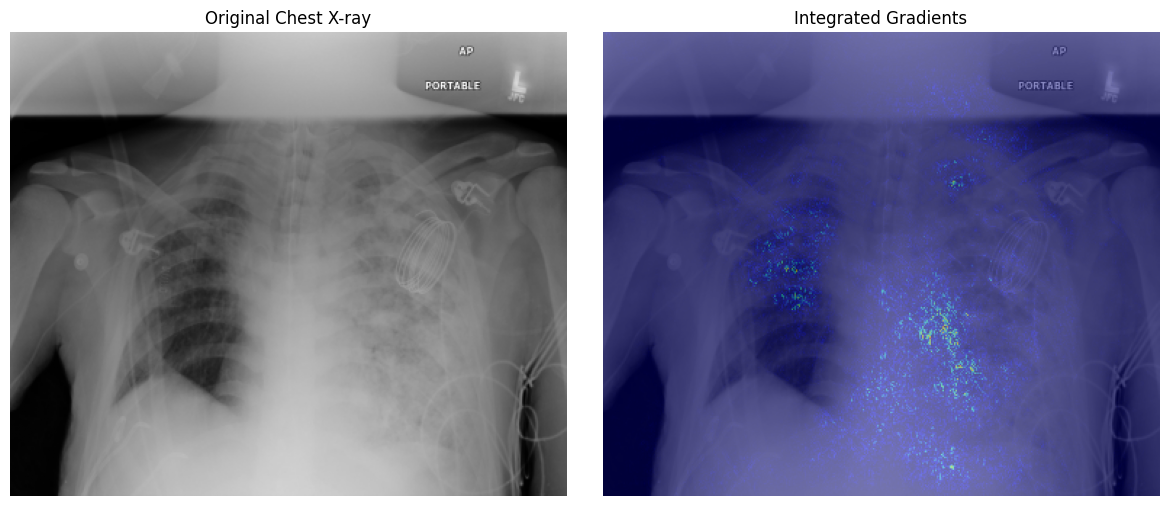

Predicted opacity probability: 0.8987
Convergence delta: 0.015446


In [ ]:
import matplotlib.pyplot as plt

# Load and resize the X-ray
image = load_dicom(sample_dicom_path)
resized_image = resize_image(image)

# Prepare model input
input_tensor = prepare_corrupted_image(
    resized_image
).unsqueeze(0).to(device)

# Initial reference: zero in normalized input space
baseline = torch.zeros_like(input_tensor)

# Calculate Integrated Gradients
attributions, convergence_delta = ig.attribute(
    input_tensor,
    baselines=baseline,
    n_steps=32,
    internal_batch_size=4,
    return_convergence_delta=True
)

# Sum the channel contributions, then take magnitude
attribution_map = (
    attributions.detach()
    .cpu()
    .numpy()[0]
    .sum(axis=0)
)

attribution_magnitude = np.abs(attribution_map)

# Normalize for visualization
attribution_magnitude /= (
    attribution_magnitude.max() + 1e-8
)

# Obtain model prediction
with torch.no_grad():
    probability = torch.sigmoid(
        model(input_tensor)
    ).item()

# Display X-ray and explanation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(resized_image, cmap="gray")
axes[0].set_title("Original Chest X-ray")
axes[0].axis("off")

axes[1].imshow(resized_image, cmap="gray")
axes[1].imshow(
    attribution_magnitude,
    cmap="jet",
    alpha=0.45
)
axes[1].set_title("Integrated Gradients")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Predicted opacity probability: {probability:.4f}")
print(f"Convergence delta: {convergence_delta.item():.6f}")

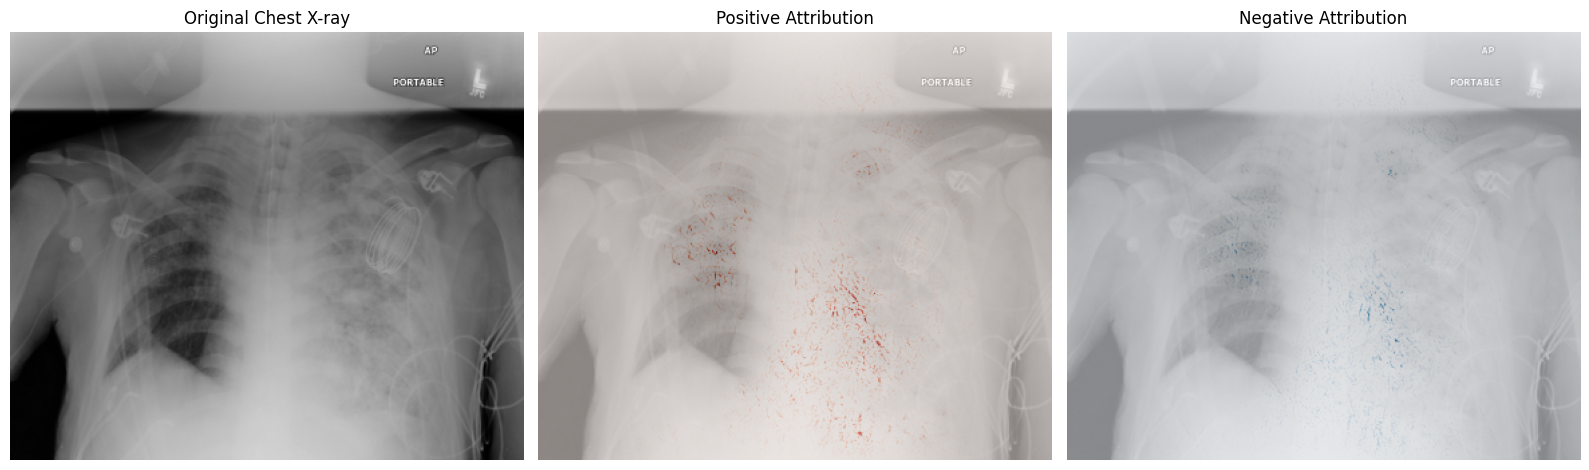

In [ ]:
# Separate positive and negative attribution
positive_attr = np.maximum(attribution_map, 0)
negative_attr = np.maximum(-attribution_map, 0)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(resized_image, cmap="gray")
axes[0].set_title("Original Chest X-ray")
axes[0].axis("off")

axes[1].imshow(resized_image, cmap="gray")
axes[1].imshow(positive_attr, cmap="Reds", alpha=0.55)
axes[1].set_title("Positive Attribution")
axes[1].axis("off")

axes[2].imshow(resized_image, cmap="gray")
axes[2].imshow(negative_attr, cmap="Blues", alpha=0.55)
axes[2].set_title("Negative Attribution")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Check numerical convergence
delta = convergence_delta.detach().cpu().item()

print(f"Predicted opacity probability: {probability:.4f}")
print(f"Convergence delta: {delta:.6f}")

# Summarize signed attributions
print(f"Total positive attribution: {positive_attr.sum():.4f}")
print(f"Total negative attribution magnitude: {negative_attr.sum():.4f}")

# Compare the total attribution with the change in model output
with torch.no_grad():
    input_logit = forward_func(input_tensor).item()
    baseline_logit = forward_func(baseline).item()

print(f"Logit difference: {input_logit - baseline_logit:.6f}")
print(f"Sum of attributions: {attribution_map.sum():.6f}")

Predicted opacity probability: 0.8987
Convergence delta: 0.015446
Total positive attribution: 243.1206
Total negative attribution magnitude: 241.4108
Logit difference: 1.694319
Sum of attributions: 1.709765



## 3. Baseline Selection and Numerical Convergence

Integrated Gradients requires a reference input, called the baseline.

Because attributions are defined relative to this reference, the choice of baseline can affect both attribution magnitude and spatial distribution.

### Baselines Examined

**Normalized-zero baseline:** A tensor of zeros in the normalized model-input space.

**Black-image baseline:** A black image in the original image-intensity space, passed through the same preprocessing pipeline as the input.

These baselines are not equivalent because the preprocessing includes normalization.

### Baseline Comparison

The following cells compare the attribution maps produced by both baselines and examine their convergence deltas.

The final pilot uses the transformed black-image baseline consistently for original and corrupted images.

This is a methodological choice rather than evidence that the black-image baseline is universally optimal for medical imaging.

### Convergence Delta

Captum reports a convergence delta describing the numerical discrepancy between the sum of attributions and the target output difference between the input and baseline.

A smaller absolute delta indicates better numerical agreement with the Integrated Gradients completeness property.

However, numerical convergence does not establish clinical correctness, explanation faithfulness, or localization quality.


In [ ]:
# Baseline A: zero in normalized model-input space
baseline_normalized_zero = torch.zeros_like(input_tensor)

# Baseline B: black image before ImageNet normalization
black_image = np.zeros_like(resized_image, dtype=np.float32)

baseline_black = (
    prepare_corrupted_image(black_image)
    .unsqueeze(0)
    .to(device)
)

# Calculate IG using the black-image baseline
attr_black, delta_black = ig.attribute(
    input_tensor,
    baselines=baseline_black,
    n_steps=32,
    internal_batch_size=4,
    return_convergence_delta=True
)

# Convert signed attributions into a 2D map
attr_black_map = (
    attr_black.detach()
    .cpu()
    .numpy()[0]
    .sum(axis=0)
)

print("Normalized-zero baseline delta:",
      convergence_delta.item())

print("Black-image baseline delta:",
      delta_black.item())

Normalized-zero baseline delta: 0.01544642448425293
Black-image baseline delta: 0.007273554801940918


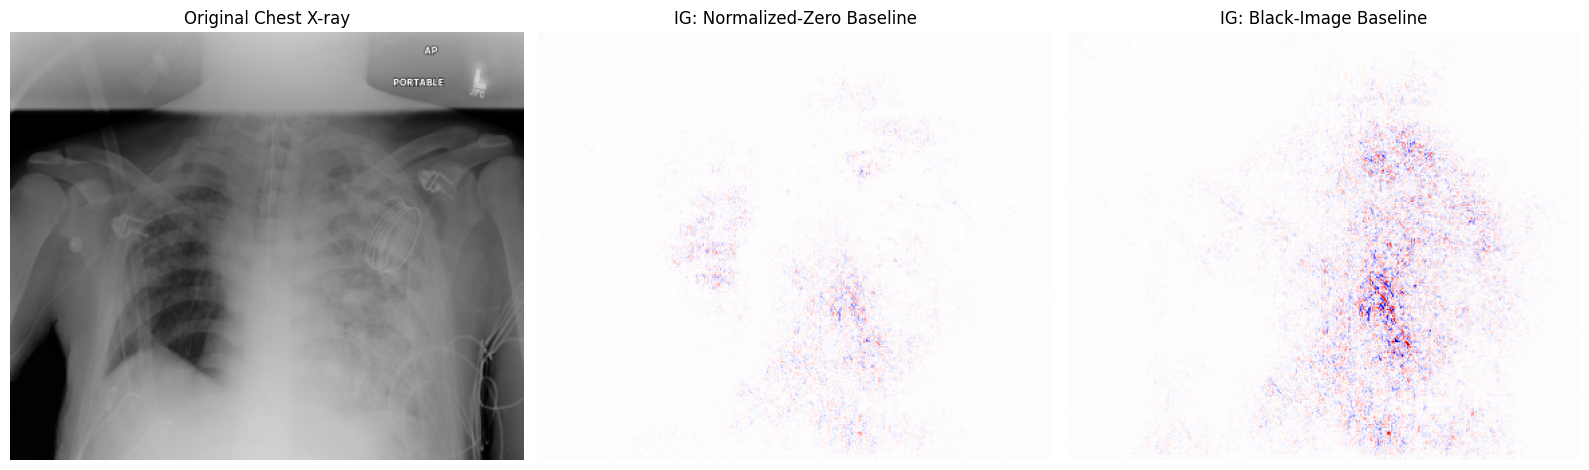

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Use one shared display scale for both attribution maps
scale = max(
    np.abs(attribution_map).max(),
    np.abs(attr_black_map).max(),
    1e-8
)

axes[0].imshow(resized_image, cmap="gray")
axes[0].set_title("Original Chest X-ray")
axes[0].axis("off")

axes[1].imshow(
    attribution_map,
    cmap="seismic",
    vmin=-scale,
    vmax=scale
)
axes[1].set_title("IG: Normalized-Zero Baseline")
axes[1].axis("off")

axes[2].imshow(
    attr_black_map,
    cmap="seismic",
    vmin=-scale,
    vmax=scale
)
axes[2].set_title("IG: Black-Image Baseline")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
with torch.no_grad():
    input_logit = forward_func(input_tensor).item()
    black_logit = forward_func(baseline_black).item()

black_delta = delta_black.detach().cpu().item()
logit_difference = input_logit - black_logit

print(f"Black-baseline convergence delta: {black_delta:.6f}")
print(f"Black-baseline logit difference: {logit_difference:.6f}")

if abs(logit_difference) > 1e-8:
    relative_error = abs(black_delta / logit_difference) * 100
    print(f"Relative convergence error: {relative_error:.2f}%")
else:
    print("Relative error undefined: logit difference is near zero.")

Black-baseline convergence delta: 0.007274
Black-baseline logit difference: 1.437095
Relative convergence error: 0.51%



## 4. Pilot Experimental Design

The Integrated Gradients pilot reuses the 12 held-out images selected for the earlier Score-CAM experiment.

### Experimental Conditions

Each image is evaluated under seven conditions:

1. Original, uncorrupted image.
2. Mild Gaussian blur.
3. Moderate Gaussian blur.
4. Severe Gaussian blur.
5. Mild Gaussian noise.
6. Moderate Gaussian noise.
7. Severe Gaussian noise.

This produces:

**12 images × 7 conditions = 84 explanation maps.**

The original condition is a reference, not a corruption.

### Controls

- The ResNet-50 model checkpoint remains fixed.
- The same explanation target is used for each image across conditions.
- The same black-image baseline and integration settings are applied.
- Gaussian noise uses a fixed random seed of 42.
- Original and corrupted images follow the same model preprocessing pipeline.

### Scope

The 12-image pilot is intended to establish the experimental workflow and inspect initial explanation behavior.

Because the images are correctly classified and the sample is small, the pilot is not sufficient for population-level conclusions about explanation reliability.


In [ ]:
# Fixed experimental settings
IG_STEPS = 32
IG_INTERNAL_BATCH_SIZE = 4
IG_BASELINE = "black_image"

# Same corruption settings as Score-CAM
print("Gaussian blur levels:")
print(BLUR_LEVELS)

print("\nGaussian noise levels:")
print(NOISE_LEVELS)

print("\nPilot images:")
print(pilot_images["pilot_group"].value_counts())

# Confirm all 12 DICOMs are available locally
missing = [
    str(uid)
    for uid in pilot_images["sop_uid"]
    if not (LOCAL_PILOT_DIR / f"{uid}.dcm").is_file()
]

print("\nMissing DICOM files:", len(missing))

if missing:
    raise FileNotFoundError(f"Missing pilot images: {missing}")

print("\nIntegrated Gradients pilot configuration ready!")

Gaussian blur levels:
{'Original': 0.0, 'Mild Blur': 0.5, 'Moderate Blur': 1.5, 'Severe Blur': 3.0}

Gaussian noise levels:
{'Original': 0.0, 'Mild Noise': 0.02, 'Moderate Noise': 0.05, 'Severe Noise': 0.1}

Pilot images:
pilot_group
Positive    6
Negative    6
Name: count, dtype: int64

Missing DICOM files: 0

Integrated Gradients pilot configuration ready!


In [ ]:
def generate_ig_explanation(resized_image, target_class=1):
    """
    Generate an Integrated Gradients explanation.

    target_class:
        1 = Lung Opacity
        0 = No Lung Opacity

    Returns:
        probability, signed attribution map,
        absolute attribution map, convergence delta
    """

    x = (
        prepare_corrupted_image(resized_image)
        .unsqueeze(0)
        .to(device)
    )

    black_image = np.zeros_like(
        resized_image, dtype=np.float32
    )

    black_baseline = (
        prepare_corrupted_image(black_image)
        .unsqueeze(0)
        .to(device)
    )

    # For binary classification:
    # opacity target = logit
    # no-opacity target = negative logit
    sign = 1 if target_class == 1 else -1

    def target_forward(inputs):
        return sign * forward_func(inputs)

    target_ig = IntegratedGradients(target_forward)

    attr, delta = target_ig.attribute(
        x,
        baselines=black_baseline,
        n_steps=IG_STEPS,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    signed_map = (
        attr.detach()
        .cpu()
        .numpy()[0]
        .sum(axis=0)
    )

    magnitude_map = np.abs(signed_map)

    with torch.no_grad():
        probability = torch.sigmoid(
            forward_func(x)
        ).item()

    return {
        "opacity_probability": probability,
        "signed_map": signed_map,
        "magnitude_map": magnitude_map,
        "convergence_delta": delta.item()
    }


print("Reusable Integrated Gradients function ready!")

Reusable Integrated Gradients function ready!


In [ ]:
# Select one image from each group
positive_row = pilot_images[
    pilot_images["pilot_group"] == "Positive"
].iloc[0]

negative_row = pilot_images[
    pilot_images["pilot_group"] == "Negative"
].iloc[0]

test_cases = [
    ("Positive", positive_row, 1),
    ("Negative", negative_row, 0)
]

ig_test_results = {}

for group, row, target_class in test_cases:

    uid = str(row["sop_uid"])
    dicom_path = LOCAL_PILOT_DIR / f"{uid}.dcm"

    image = resize_image(load_dicom(dicom_path))

    result = generate_ig_explanation(
        image,
        target_class=target_class
    )

    ig_test_results[group] = {
        "image": image,
        "result": result,
        "uid": uid
    }

    print(f"\n{group} image")
    print(f"Opacity probability: {result['opacity_probability']:.4f}")
    print(f"Convergence delta: {result['convergence_delta']:.6f}")
    print(f"Attribution shape: {result['signed_map'].shape}")


Positive image
Opacity probability: 0.8987
Convergence delta: 0.007273
Attribution shape: (320, 384)

Negative image
Opacity probability: 0.1332
Convergence delta: 0.013484
Attribution shape: (320, 384)


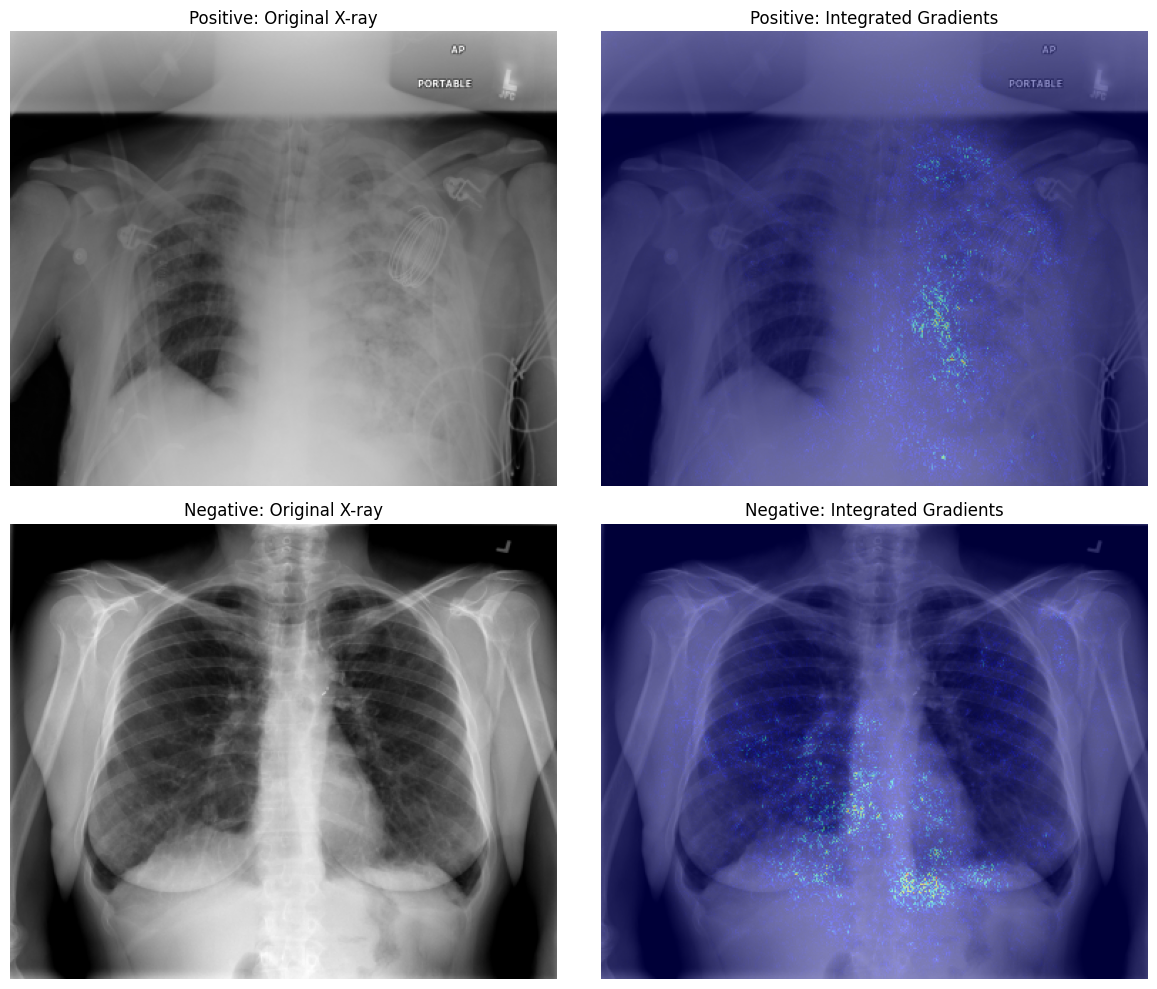

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, group in enumerate(["Positive", "Negative"]):

    data = ig_test_results[group]
    image = data["image"]
    result = data["result"]

    magnitude = result["magnitude_map"]

    # Normalize for display only
    display_map = magnitude / (magnitude.max() + 1e-8)

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"{group}: Original X-ray")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image, cmap="gray")
    axes[i, 1].imshow(
        display_map,
        cmap="jet",
        alpha=0.45
    )
    axes[i, 1].set_title(f"{group}: Integrated Gradients")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for group, data in ig_test_results.items():
    uid = data["uid"]
    result = data["result"]

    np.save(
        IG_DIR / f"{group.lower()}_baseline_signed.npy",
        result["signed_map"]
    )

    np.save(
        IG_DIR / f"{group.lower()}_baseline_magnitude.npy",
        result["magnitude_map"]
    )

print("Both Integrated Gradients test explanations saved!")
print("Saved to:", IG_DIR)

Both Integrated Gradients test explanations saved!
Saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/IntegratedGradients


In [ ]:
for group in ["positive", "negative"]:
    for kind in ["signed", "magnitude"]:
        path = IG_DIR / f"{group}_baseline_{kind}.npy"

        print(
            path.name,
            "| Exists:", path.is_file()
        )

positive_baseline_signed.npy | Exists: True
positive_baseline_magnitude.npy | Exists: True
negative_baseline_signed.npy | Exists: True
negative_baseline_magnitude.npy | Exists: True


In [ ]:
for group, data in ig_test_results.items():
    result = data["result"]

    np.savez_compressed(
        IG_DIR / f"{group.lower()}_original_ig.npz",
        signed_map=result["signed_map"],
        magnitude_map=result["magnitude_map"],
        opacity_probability=result["opacity_probability"],
        convergence_delta=result["convergence_delta"],
        target_class=1 if group == "Positive" else 0
    )

print("Saved both original-image explanations to Google Drive.")

Saved both original-image explanations to Google Drive.


In [ ]:
import time

# Use the first positive pilot image
test_image = ig_test_results["Positive"]["image"]

# Synchronize GPU before timing
torch.cuda.synchronize()

start = time.perf_counter()

benchmark_result = generate_ig_explanation(
    test_image,
    target_class=1
)

torch.cuda.synchronize()

elapsed = time.perf_counter() - start

print(f"Time per explanation: {elapsed:.2f} seconds")
print(f"Estimated time for 82 explanations: {82 * elapsed / 60:.1f} minutes")
print(f"Convergence delta: {benchmark_result['convergence_delta']:.6f}")

Time per explanation: 0.73 seconds
Estimated time for 82 explanations: 1.0 minutes
Convergence delta: 0.007275


In [ ]:
import time

conditions = [
    ("Original", "Original", 0.0)
]

conditions += [
    ("Blur", name, sigma)
    for name, sigma in BLUR_LEVELS.items()
    if name != "Original"
]

conditions += [
    ("Noise", name, sigma)
    for name, sigma in NOISE_LEVELS.items()
    if name != "Original"
]

MAP_DIR = IG_DIR / "Maps"
MAP_DIR.mkdir(parents=True, exist_ok=True)

start_time = time.perf_counter()
completed = 0
skipped = 0

for _, row in pilot_images.iterrows():

    uid = str(row["sop_uid"])
    group = str(row["pilot_group"])
    target_class = 1 if group == "Positive" else 0

    dicom_path = LOCAL_PILOT_DIR / f"{uid}.dcm"
    original_image = resize_image(load_dicom(dicom_path))

    for corruption, condition, sigma in conditions:

        output_path = MAP_DIR / f"{uid}_{corruption}_{condition.replace(' ', '_')}.npz"

        if output_path.exists():
            skipped += 1
            continue

        if corruption == "Blur":
            image = apply_gaussian_blur(original_image, sigma)

        elif corruption == "Noise":
            image = apply_gaussian_noise(
                original_image,
                sigma,
                seed=42
            )

        else:
            image = original_image.copy()

        result = generate_ig_explanation(
            image,
            target_class=target_class
        )

        np.savez_compressed(
            output_path,
            signed_map=result["signed_map"],
            magnitude_map=result["magnitude_map"],
            opacity_probability=result["opacity_probability"],
            convergence_delta=result["convergence_delta"],
            target_class=target_class,
            corruption=corruption,
            condition=condition,
            sigma=sigma,
            uid=uid,
            pilot_group=group
        )

        completed += 1

    print(f"Finished {group} image: {uid}")

elapsed = time.perf_counter() - start_time

print("\nExperiment finished!")
print("New explanations:", completed)
print("Previously saved:", skipped)
print("Total files:", len(list(MAP_DIR.glob("*.npz"))))
print(f"Elapsed time: {elapsed:.1f} seconds")

Finished Positive image: 1.2.276.0.7230010.3.1.4.8323329.2175.1517874295.55234
Finished Positive image: 1.2.276.0.7230010.3.1.4.8323329.23771.1517874449.868000
Finished Positive image: 1.2.276.0.7230010.3.1.4.8323329.2309.1517874295.825680
Finished Positive image: 1.2.276.0.7230010.3.1.4.8323329.11891.1517874361.753854
Finished Positive image: 1.2.276.0.7230010.3.1.4.8323329.3251.1517874301.45911
Finished Positive image: 1.2.276.0.7230010.3.1.4.8323329.25616.1517874465.891399
Finished Negative image: 1.2.276.0.7230010.3.1.4.8323329.13578.1517874373.432432
Finished Negative image: 1.2.276.0.7230010.3.1.4.8323329.8295.1517874336.602922
Finished Negative image: 1.2.276.0.7230010.3.1.4.8323329.6215.1517874324.370893
Finished Negative image: 1.2.276.0.7230010.3.1.4.8323329.8937.1517874340.337163
Finished Negative image: 1.2.276.0.7230010.3.1.4.8323329.24097.1517874452.530039
Finished Negative image: 1.2.276.0.7230010.3.1.4.8323329.14212.1517874378.177644

Experiment finished!
New explanatio


## 5. Explanation Stability Evaluation

Explanation stability measures the similarity between attribution-magnitude maps generated for an original image and its corrupted counterpart.

The notebook uses Spearman rank correlation:

$$
S = \rho_{\text{Spearman}}
\left(
\operatorname{vec}(|A_{\text{original}}|),
\operatorname{vec}(|A_{\text{corrupted}}|)
\right)
$$

Here, \(A\) denotes the channel-aggregated signed attribution map, and `vec` denotes flattening the spatial map into a vector.

A correlation close to 1 indicates that the spatial ranking of attribution magnitudes is largely preserved.

### Interpretation

High explanation stability does not necessarily mean the explanation remains concentrated in medically annotated regions.

Similarly, low stability does not automatically indicate reduced localization alignment.

The project therefore evaluates stability and localization as separate dimensions.

The original image is assigned a reference stability score of 1.0.


In [ ]:
from scipy.stats import spearmanr

stability_records = []

for _, row in pilot_images.iterrows():

    uid = str(row["sop_uid"])
    group = str(row["pilot_group"])

    original_path = MAP_DIR / f"{uid}_Original_Original.npz"

    with np.load(original_path) as data:
        original_map = data["magnitude_map"].copy()

    for corruption, condition, sigma in conditions:

        result_path = (
            MAP_DIR /
            f"{uid}_{corruption}_{condition.replace(' ', '_')}.npz"
        )

        with np.load(result_path) as data:
            current_map = data["magnitude_map"].copy()
            probability = float(data["opacity_probability"])
            delta = float(data["convergence_delta"])

        if corruption == "Original":
            similarity = 1.0
        else:
            similarity = spearmanr(
                original_map.ravel(),
                current_map.ravel()
            ).statistic

        stability_records.append({
            "sop_uid": uid,
            "pilot_group": group,
            "corruption": corruption,
            "condition": condition,
            "sigma": sigma,
            "opacity_probability": probability,
            "explanation_similarity": similarity,
            "convergence_delta": delta
        })

ig_stability = pd.DataFrame(stability_records)

ig_stability.to_csv(
    IG_DIR / "ig_stability_results.csv",
    index=False
)

print("Total rows:", len(ig_stability))
print("Saved stability results!")
print(ig_stability.head())

Total rows: 84
Saved stability results!
                                             sop_uid pilot_group corruption  \
0  1.2.276.0.7230010.3.1.4.8323329.2175.151787429...    Positive   Original   
1  1.2.276.0.7230010.3.1.4.8323329.2175.151787429...    Positive       Blur   
2  1.2.276.0.7230010.3.1.4.8323329.2175.151787429...    Positive       Blur   
3  1.2.276.0.7230010.3.1.4.8323329.2175.151787429...    Positive       Blur   
4  1.2.276.0.7230010.3.1.4.8323329.2175.151787429...    Positive      Noise   

       condition  sigma  opacity_probability  explanation_similarity  \
0       Original   0.00             0.898721                1.000000   
1      Mild Blur   0.50             0.893324                0.856397   
2  Moderate Blur   1.50             0.712182                0.628193   
3    Severe Blur   3.00             0.579108                0.506274   
4     Mild Noise   0.02             0.631496                0.585013   

   convergence_delta  
0           0.007274  
1     

In [ ]:
blur_results = ig_stability[
    ig_stability["corruption"].isin(["Original", "Blur"])
].copy()

noise_results = ig_stability[
    ig_stability["corruption"].isin(["Original", "Noise"])
].copy()

blur_results["experiment"] = "Gaussian Blur"
noise_results["experiment"] = "Gaussian Noise"

combined_results = pd.concat(
    [blur_results, noise_results],
    ignore_index=True
)

aggregations = {
    "mean_opacity_probability": (
        "opacity_probability", "mean"
    ),
    "mean_spearman_similarity": (
        "explanation_similarity", "mean"
    ),
    "mean_abs_convergence_delta": (
        "convergence_delta",
        lambda x: np.abs(x).mean()
    ),
    "n_images": ("sop_uid", "nunique")
}

if "pearson_similarity" in combined_results.columns:
    aggregations["mean_pearson_similarity"] = (
        "pearson_similarity", "mean"
    )

ig_summary = (
    combined_results
    .groupby(
        ["experiment", "pilot_group", "condition"],
        as_index=False
    )
    .agg(**aggregations)
)

ig_summary.to_csv(
    IG_DIR / "ig_stability_summary.csv",
    index=False
)

print("Summary rows:", len(ig_summary))
display(ig_summary.round(4))

Summary rows: 16


,experiment,pilot_group,condition,mean_opacity_probability,mean_spearman_similarity,mean_abs_convergence_delta,n_images
0,Gaussian Blur,Negative,Mild Blur,0.1090,0.8606,0.0149,6
1,Gaussian Blur,Negative,Moderate Blur,0.3733,0.6628,0.0141,6
2,Gaussian Blur,Negative,Original,0.0852,1.0000,0.0145,6
3,Gaussian Blur,Negative,Severe Blur,0.5769,0.5741,0.0048,6
4,Gaussian Blur,Positive,Mild Blur,0.9710,0.8650,0.0132,6
5,Gaussian Blur,Positive,Moderate Blur,0.9131,0.6553,0.0128,6
6,Gaussian Blur,Positive,Original,0.9705,1.0000,0.0353,6
7,Gaussian Blur,Positive,Severe Blur,0.8144,0.5918,0.0086,6
8,Gaussian Noise,Negative,Mild Noise,0.2437,0.6470,0.0160,6
9,Gaussian Noise,Negative,Moderate Noise,0.4102,0.5205,0.0070,6



## 6. Localization Alignment with Radiologist Annotations

Localization alignment evaluates how much attribution magnitude lies within radiologist-annotated lung-opacity bounding boxes.

The analysis is restricted to the six positive pilot images with opacity annotations.

The metric is:

$$
\text{Alignment} =
\frac{\sum_{p \in B}|A(p)|}
{\sum_{p \in I}|A(p)|}
$$

where:

- \(A(p)\) is the channel-aggregated attribution at pixel \(p\).
- \(B\) is the union of annotated opacity bounding-box regions.
- \(I\) is the full image.

Higher values indicate that a greater proportion of attribution magnitude falls inside the annotated regions.

### Interpretation and Limitations

Bounding boxes are approximate spatial references rather than pixel-level lesion segmentation masks.

Attribution outside the boxes is not automatically irrelevant, and overlap with the boxes does not establish clinical correctness.

Localization alignment is therefore treated as a spatial comparison measure rather than a direct measure of explanation faithfulness.

The same metric is used across the explanation methods in the larger audit.


In [ ]:
import json

ANNOTATION_PATH = (
    DATA_DIR /
    "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
)

with open(ANNOTATION_PATH, "r") as f:
    annotations = json.load(f)

annotation_records = annotations["datasets"][0]["annotations"]

print("Total annotation records:", len(annotation_records))
print("\nExample annotation keys:")
print(list(annotation_records[0].keys()))

opacity_lookup = build_opacity_lookup(annotation_records)

print("\nNumber of images with opacity annotations:",
      len(opacity_lookup))

positive_uids = (
    pilot_images.loc[
        pilot_images["pilot_group"] == "Positive",
        "sop_uid"
    ]
    .astype(str)
    .tolist()
)

print("\nPositive pilot images with annotations:")
for uid in positive_uids:
    boxes = opacity_lookup.get(uid, [])
    print(uid[-18:], "| Boxes:", len(boxes))

Total annotation records: 83809

Example annotation keys:
['id', 'createdAt', 'createdById', 'updatedAt', 'updatedById', 'machineLearningModelId', 'StudyInstanceUID', 'SeriesInstanceUID', 'SOPInstanceUID', 'labelId', 'annotationNumber', 'height', 'width', 'data', 'note', 'radlexTagIds', 'reviewsPositiveCount', 'reviewsNegativeCount']

Number of images with opacity annotations: 7106

Positive pilot images with annotations:
5.1517874295.55234 | Boxes: 1
.1517874449.868000 | Boxes: 2
.1517874295.825680 | Boxes: 2
.1517874361.753854 | Boxes: 1
1.1517874301.45911 | Boxes: 2
.1517874465.891399 | Boxes: 2


In [ ]:
alignment_records = []

for _, row in pilot_images.iterrows():

    if row["pilot_group"] != "Positive":
        continue

    uid = str(row["sop_uid"])
    boxes = opacity_lookup[uid]

    for corruption, condition, sigma in conditions:

        result_path = (
            MAP_DIR /
            f"{uid}_{corruption}_{condition.replace(' ', '_')}.npz"
        )

        with np.load(result_path) as data:
            magnitude_map = data["magnitude_map"].copy()

        alignment = calculate_alignment(
            magnitude_map,
            boxes
        )

        alignment_records.append({
            "sop_uid": uid,
            "corruption": corruption,
            "condition": condition,
            "sigma": sigma,
            "localization_alignment": alignment
        })

ig_alignment = pd.DataFrame(alignment_records)

ig_alignment.to_csv(
    IG_DIR / "ig_localization_alignment.csv",
    index=False
)

print("Total rows:", len(ig_alignment))
display(ig_alignment.head())

Total rows: 42


,sop_uid,corruption,condition,sigma,localization_alignment
0,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Original,Original,0.00,0.471095
1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Blur,Mild Blur,0.50,0.478937
2,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Blur,Moderate Blur,1.50,0.539998
3,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Blur,Severe Blur,3.00,0.398479
4,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Noise,Mild Noise,0.02,0.375003


In [ ]:
blur_alignment = ig_alignment[
    ig_alignment["corruption"].isin(["Original", "Blur"])
].copy()

noise_alignment = ig_alignment[
    ig_alignment["corruption"].isin(["Original", "Noise"])
].copy()

blur_alignment["experiment"] = "Gaussian Blur"
noise_alignment["experiment"] = "Gaussian Noise"

combined_alignment = pd.concat(
    [blur_alignment, noise_alignment],
    ignore_index=True
)

ig_alignment_summary = (
    combined_alignment
    .groupby(["experiment", "condition"], as_index=False)
    .agg(
        mean_alignment=("localization_alignment", "mean"),
        std_alignment=("localization_alignment", "std"),
        n_images=("sop_uid", "nunique")
    )
)

ig_alignment_summary.to_csv(
    IG_DIR / "ig_localization_summary.csv",
    index=False
)

display(ig_alignment_summary.round(4))

,experiment,condition,mean_alignment,std_alignment,n_images
0,Gaussian Blur,Mild Blur,0.3949,0.1885,6
1,Gaussian Blur,Moderate Blur,0.3901,0.2022,6
2,Gaussian Blur,Original,0.4067,0.1881,6
3,Gaussian Blur,Severe Blur,0.3727,0.1943,6
4,Gaussian Noise,Mild Noise,0.3609,0.1885,6
5,Gaussian Noise,Moderate Noise,0.1854,0.1242,6
6,Gaussian Noise,Original,0.4067,0.1881,6
7,Gaussian Noise,Severe Noise,0.1523,0.0995,6


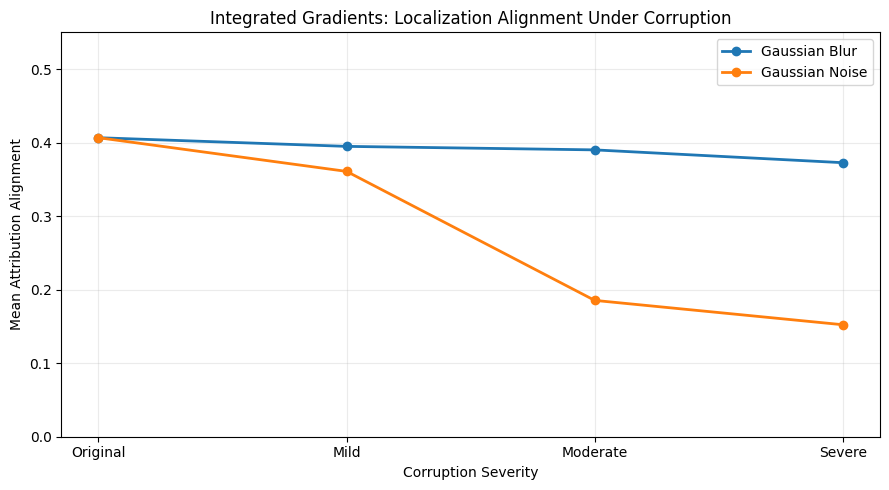

In [ ]:
import matplotlib.pyplot as plt

severity_order = ["Original", "Mild", "Moderate", "Severe"]

fig, ax = plt.subplots(figsize=(9, 5))

for experiment in ["Gaussian Blur", "Gaussian Noise"]:
    subset = ig_alignment_summary[
        ig_alignment_summary["experiment"] == experiment
    ].copy()

    subset["severity"] = (
        subset["condition"].str.split().str[0]
    )

    subset["severity"] = pd.Categorical(
        subset["severity"],
        categories=severity_order,
        ordered=True
    )

    subset = subset.sort_values("severity")

    ax.plot(
        subset["severity"].astype(str),
        subset["mean_alignment"],
        marker="o",
        linewidth=2,
        label=experiment
    )

ax.set_title(
    "Integrated Gradients: Localization Alignment Under Corruption"
)
ax.set_xlabel("Corruption Severity")
ax.set_ylabel("Mean Attribution Alignment")
ax.set_ylim(0, 0.55)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    IG_DIR / "ig_localization_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Pilot Results and Interpretation

The pilot examines the behavior of Integrated Gradients explanations under increasing Gaussian blur and Gaussian noise.

### Localization Findings

The recorded pilot summary reports the following mean localization alignment values for the six positive images:

| Condition | Mean localization alignment |
|---|---:|
| Original images | 0.4067 |
| Severe Gaussian blur | 0.3727 |
| Severe Gaussian noise | 0.1523 |

The mean localization alignment declined more substantially under severe Gaussian noise than under severe Gaussian blur in this pilot.

### Interpretation

These findings suggest that image corruption can affect the spatial distribution of IG attribution, even when the classifier continues producing predictions.

However, this pilot alone does not establish the frequency of high-stability, low-localization disagreement in the broader test sample.

The final disagreement analysis is conducted separately using 150 annotated positive images and all three explanation methods.

### Limitations

- Only six positive images contribute to localization statistics.
- The pilot is restricted to correctly classified cases.
- Blur and noise severity levels are not calibrated to equivalent image degradation.
- Results may depend on baseline choice and attribution aggregation.
- Localization alignment does not establish explanation faithfulness.


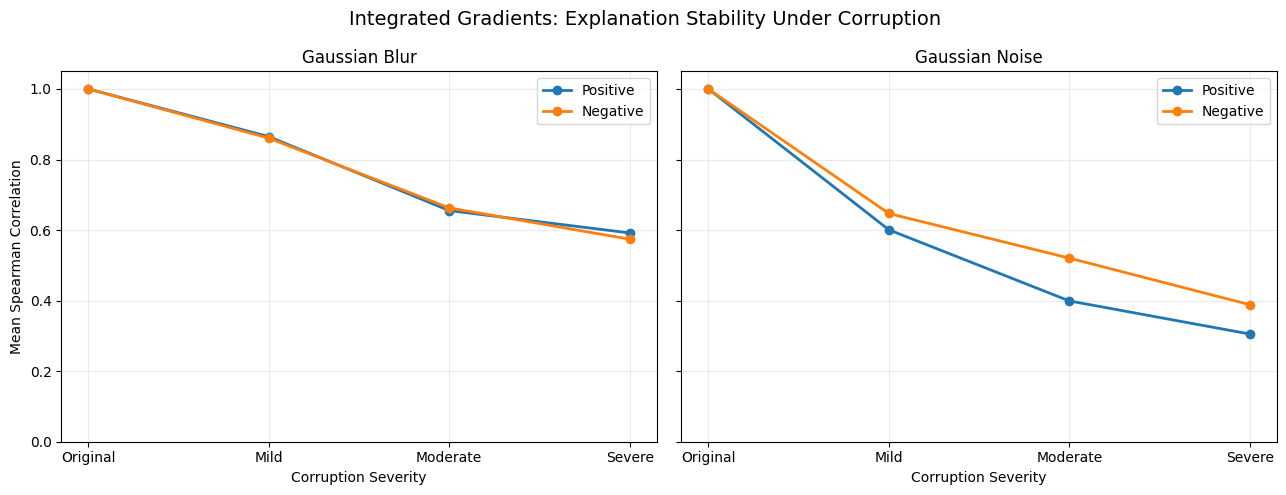

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

severity_order = ["Original", "Mild", "Moderate", "Severe"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, experiment in zip(
    axes,
    ["Gaussian Blur", "Gaussian Noise"]
):
    for group in ["Positive", "Negative"]:

        subset = ig_summary[
            (ig_summary["experiment"] == experiment) &
            (ig_summary["pilot_group"] == group)
        ].copy()

        subset["severity"] = (
            subset["condition"].str.split().str[0]
        )

        subset["severity"] = pd.Categorical(
            subset["severity"],
            categories=severity_order,
            ordered=True
        )

        subset = subset.sort_values("severity")

        ax.plot(
            subset["severity"].astype(str),
            subset["mean_spearman_similarity"],
            marker="o",
            linewidth=2,
            label=group
        )

    ax.set_title(experiment)
    ax.set_xlabel("Corruption Severity")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Mean Spearman Correlation")

fig.suptitle(
    "Integrated Gradients: Explanation Stability Under Corruption",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    IG_DIR / "ig_spearman_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 8. Saved Outputs and Reproducibility Verification

The notebook saves Integrated Gradients attribution maps and summary statistics to:

`Results/IntegratedGradients/`

### Expected Outputs

- `ig_stability_results.csv`: Image-level explanation stability and prediction results.
- `ig_stability_summary.csv`: Aggregated stability results.
- `ig_localization_alignment.csv`: Positive-image localization alignment.
- `ig_localization_summary.csv`: Aggregated localization results.
- `ig_spearman_stability.png`: Stability visualization.
- `ig_localization_comparison.png`: Localization visualization.
- `Maps/`: Saved attribution maps for original and corrupted images.

The expected map count is 84, corresponding to 12 images across seven conditions.

The experiment skips map generation when the corresponding output file already exists. This supports recovery from interrupted runs but requires the researcher to verify that saved maps were generated using the intended model, baseline, and configuration.

### Conclusion

This notebook establishes the Integrated Gradients component of the explanation-robustness evaluation.

It demonstrates how attribution maps can be generated and compared under controlled Gaussian blur and noise conditions.

The pilot provides preliminary evidence that localization alignment can deteriorate under image corruption, particularly severe Gaussian noise.

The larger project evaluates whether these localization changes can occur even when explanation stability remains high.

### Next Steps

Compare Integrated Gradients with Score-CAM and Occlusion Sensitivity on the larger held-out sample, then apply the joint stability–localization disagreement criterion.


In [ ]:
required_files = [
    "ig_stability_results.csv",
    "ig_stability_summary.csv",
    "ig_localization_alignment.csv",
    "ig_localization_summary.csv",
    "ig_spearman_stability.png",
    "ig_localization_comparison.png",
]

for filename in required_files:
    path = IG_DIR / filename
    print(
        "✓" if path.exists() else "✗",
        filename
    )

map_count = len(list((IG_DIR / "Maps").glob("*.npz")))

print(f"\nSaved attribution maps: {map_count}/84")
print("Ready for comparison:", map_count == 84)

✓ ig_stability_results.csv
✓ ig_stability_summary.csv
✓ ig_localization_alignment.csv
✓ ig_localization_summary.csv
✓ ig_spearman_stability.png
✓ ig_localization_comparison.png

Saved attribution maps: 84/84
Ready for comparison: True
